In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [45]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"

columns = [
    "Variance",
    "Skewness",
    "Curtosis",
    "Entropy",
    "Class"
]

data = pd.read_csv(url, header=None, names=columns)

print("Dataset shape:", data.shape)
display(data.head())

Dataset shape: (1372, 5)


,Variance,Skewness,Curtosis,Entropy,Class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


## Data Understanding

The Banknote Authentication dataset contains 1,372 records and five columns. Four columns are input features, while the Class column is the target variable.

The target contains two classes, making this dataset suitable for binary classification using Logistic Regression.

In [46]:
# Check dataset information
print("Dataset shape:", data.shape)

print("\nMissing values:")
print(data.isnull().sum())

print("\nClass distribution:")
print(data["Class"].value_counts())

Dataset shape: (1372, 5)

Missing values:
Variance    0
Skewness    0
Curtosis    0
Entropy     0
Class       0
dtype: int64

Class distribution:
Class
0    762
1    610
Name: count, dtype: int64


In [47]:
# Select input features
X = data[["Variance", "Skewness", "Curtosis", "Entropy"]].to_numpy()

# Select target variable
y = data["Class"].to_numpy()

print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nFirst five input samples:")
print(X[:5])

print("\nFirst five target values:")
print(y[:5])

Input shape: (1372, 4)
Target shape: (1372,)

First five input samples:
[[ 3.6216   8.6661  -2.8073  -0.44699]
 [ 4.5459   8.1674  -2.4586  -1.4621 ]
 [ 3.866   -2.6383   1.9242   0.10645]
 [ 3.4566   9.5228  -4.0112  -3.5944 ]
 [ 0.32924 -4.4552   4.5718  -0.9888 ]]

First five target values:
[0 0 0 0 0]


In [48]:
# Shuffle dataset indices
np.random.seed(42)
indices = np.random.permutation(len(X))

# Calculate split point
split_index = int(0.8 * len(X))

# Divide indices
train_indices = indices[:split_index]
test_indices = indices[split_index:]

# Create training and testing data
X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1097
Testing samples: 275


In [49]:
# Calculate mean and standard deviation from training data
mean = np.mean(X_train, axis=0)
std = np.std(X_train, axis=0)

# Prevent division by zero
std[std == 0] = 1

# Standardize training and testing data
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print("First five standardized samples:")
print(X_train[:5])

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

First five standardized samples:
[[ 0.36831544  0.73384058 -0.34273316 -0.55457552]
 [-0.27979401  1.04533765 -1.01908759 -0.60992168]
 [-0.16400539  0.85318916 -0.77162576 -0.90296949]
 [-0.79834612  1.68094999  0.40843051 -1.72446262]
 [ 0.66992815  1.24729655 -1.0451929  -0.10522301]]
Training data shape: (1097, 4)
Testing data shape: (275, 4)


## Prediction Using the Sigmoid Function

In Logistic Regression, the sigmoid function converts a linear combination of input features, weights, and bias into a probability between 0 and 1.

The predicted probability is calculated using:

\[
z = Xw + b
\]

\[
\sigma(z) = \frac{1}{1 + e^{-z}}
\]

If the predicted probability is greater than or equal to 0.5, the predicted class is 1. Otherwise, the predicted class is 0.

In [50]:
# Initialize weights and bias
weights = np.zeros(X_train.shape[1])
bias = 0.0

# Sigmoid function
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

# Prediction function
def predict_probability(X, weights, bias):
    z = np.dot(X, weights) + bias
    return sigmoid(z)

# Convert probabilities into class labels
def predict_class(X, weights, bias):
    probabilities = predict_probability(X, weights, bias)
    return (probabilities >= 0.5).astype(int)

# Make initial predictions
initial_probabilities = predict_probability(
    X_train, weights, bias
)

initial_predictions = predict_class(
    X_train, weights, bias
)

print("First five predicted probabilities:")
print(initial_probabilities[:5])

print("First five predicted classes:")
print(initial_predictions[:5])

print("First five actual classes:")
print(y_train[:5])

First five predicted probabilities:
[0.5 0.5 0.5 0.5 0.5]
First five predicted classes:
[1 1 1 1 1]
First five actual classes:
[0 0 0 0 0]


## Cost Function

The cost function measures how far the model's predicted probabilities are from the actual target values.

For Logistic Regression, we use Binary Cross-Entropy:

\[
J(w,b)=-\frac{1}{m}\sum_{i=1}^{m}
\left[y_i\log(p_i)+(1-y_i)\log(1-p_i)\right]
\]

A lower cost generally indicates better predictions on the data being evaluated.

In [51]:
# Calculate binary cross-entropy cost
def compute_cost(X, y, weights, bias):
    m = len(y)

    probabilities = predict_probability(X, weights, bias)

    # Avoid log(0)
    probabilities = np.clip(
        probabilities, 1e-15, 1 - 1e-15
    )

    cost = -np.sum(
        y * np.log(probabilities)
        + (1 - y) * np.log(1 - probabilities)
    ) / m

    return cost

# Calculate initial cost
initial_cost = compute_cost(
    X_train, y_train, weights, bias
)

print("Initial Cost:", initial_cost)

Initial Cost: 0.6931471805599453


## Gradient Descent

Gradient Descent is an optimization algorithm that updates the weights and bias to minimize the cost function.

The gradients are calculated as:

\[
dw=\frac{1}{m}X^T(p-y)
\]

\[
db=\frac{1}{m}\sum_{i=1}^{m}(p_i-y_i)
\]

The parameters are updated using:

\[
w=w-\alpha dw
\]

\[
b=b-\alpha db
\]

Here, \(\alpha\) is the learning rate, which controls the size of each update.

In [52]:
def gradient_descent(X, y, weights, bias,
                     learning_rate, iterations):

    m = len(y)
    cost_history = []

    for i in range(iterations):

        # Make predictions
        probabilities = predict_probability(
            X, weights, bias
        )

        # Calculate errors
        errors = probabilities - y

        # Calculate gradients
        dw = np.dot(X.T, errors) / m
        db = np.sum(errors) / m

        # Update weights and bias
        weights = weights - learning_rate * dw
        bias = bias - learning_rate * db

        # Store cost every 100 iterations
        if (i + 1) % 100 == 0:
            cost = compute_cost(X, y, weights, bias)
            cost_history.append(cost)

    return weights, bias, cost_history

In [53]:
# Set training parameters
learning_rate = 0.1
iterations = 5000

# Reset weights and bias before training
weights = np.zeros(X_train.shape[1])
bias = 0.0

# Train the model
weights, bias, cost_history = gradient_descent(
    X_train,
    y_train,
    weights,
    bias,
    learning_rate,
    iterations
)

print("Training completed!")
print("Final weights:", weights)
print("Final bias:", bias)

final_cost = compute_cost(
    X_train, y_train, weights, bias
)

print("Final Training Cost:", final_cost)

Training completed!
Final weights: [-5.15809265 -5.2543109  -4.88821026  0.2839488 ]
Final bias: -1.7394936422889302
Final Training Cost: 0.04565629736952308


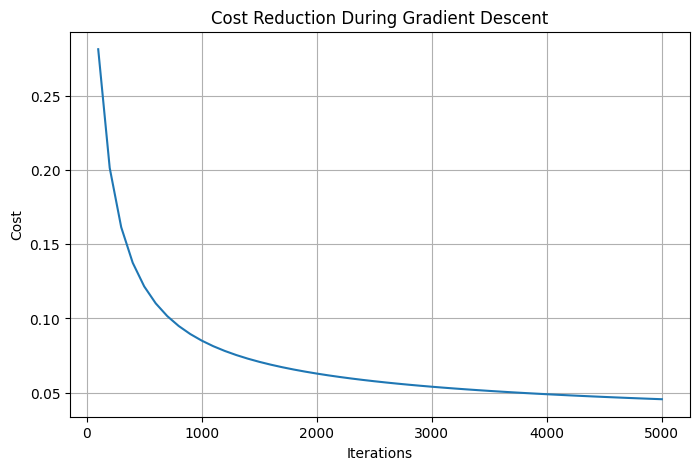

In [54]:
plt.figure(figsize=(8, 5))

plt.plot(
    np.arange(1, len(cost_history) + 1) * 100,
    cost_history
)

plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Cost Reduction During Gradient Descent")
plt.grid(True)
plt.show()

In [55]:
# Make predictions on test data
test_probabilities = predict_probability(
    X_test, weights, bias
)

test_predictions = (
    test_probabilities >= 0.5
).astype(int)

# Calculate accuracy
correct_predictions = np.sum(
    test_predictions == y_test
)

accuracy = (
    correct_predictions / len(y_test)
) * 100

print("Correct Predictions:", correct_predictions)
print("Total Test Samples:", len(y_test))
print("Test Accuracy:", round(accuracy, 2), "%")

Correct Predictions: 271
Total Test Samples: 275
Test Accuracy: 98.55 %


## Model Evaluation Using Confusion Matrix

A confusion matrix compares the actual class labels with the predicted class labels. It helps identify correct and incorrect classifications for both classes.

Confusion Matrix:
[[139   4]
 [  0 132]]


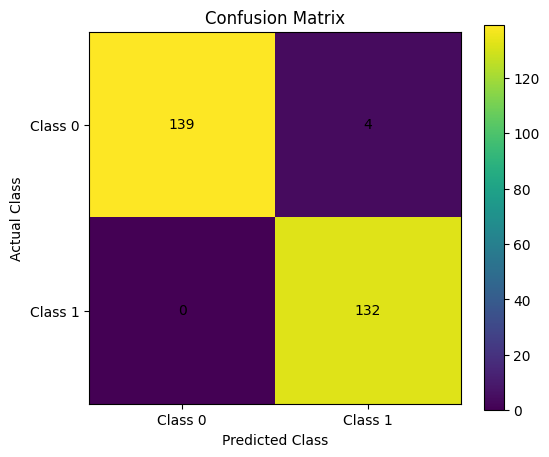

In [56]:
# Create confusion matrix from scratch
cm = np.zeros((2, 2), dtype=int)

for actual, predicted in zip(y_test, test_predictions):
    cm[actual, predicted] += 1

print("Confusion Matrix:")
print(cm)

# Visualize the confusion matrix
plt.figure(figsize=(6, 5))
plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks([0, 1], ["Class 0", "Class 1"])
plt.yticks([0, 1], ["Class 0", "Class 1"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

## Additional Evaluation Metrics

Accuracy measures the proportion of correct predictions. Precision measures how many predicted positive cases were actually positive. Recall measures how many actual positive cases were correctly identified. The F1-score combines precision and recall into a single metric.

In [57]:
# Extract confusion matrix values
TN = cm[0, 0]
FP = cm[0, 1]
FN = cm[1, 0]
TP = cm[1, 1]

# Calculate evaluation metrics
accuracy = (TP + TN) / (TP + TN + FP + FN)

precision = TP / (TP + FP) if (TP + FP) > 0 else 0

recall = TP / (TP + FN) if (TP + FN) > 0 else 0

f1_score = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0 else 0
)

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1-Score:", round(f1_score * 100, 2), "%")

Accuracy: 98.55 %
Precision: 97.06 %
Recall: 100.0 %
F1-Score: 98.51 %


## Conclusion

In this assignment, Logistic Regression was implemented from scratch using Python, NumPy, and Pandas without using Scikit-learn.

The Banknote Authentication dataset was used for binary classification. The dataset contained 1,372 records and four input features: Variance, Skewness, Curtosis, and Entropy. The data was divided into training and testing sets, and the input features were standardized.

The model was implemented using the sigmoid function for prediction, binary cross-entropy for the cost function, and gradient descent to update the weights and bias.

The initial training cost was approximately 0.69315, while the final training cost decreased to approximately 0.04566. The model correctly classified 271 out of 275 test samples, achieving a test accuracy of 98.55%.

The confusion matrix and additional evaluation metrics were used to examine the model's classification performance. This assignment demonstrates the working principles of Logistic Regression and how gradient descent can optimize a classification model using real-world data.